# Paprastosios pušies (*Pinus sylvestris*) tinkamumo projektas
## 1 dalis. GBIF duomenų įkėlimas ir peržiūra

Šiame sąsiuvinyje:
1. įkeliame GBIF atsisiųstą failą,
2. pažiūrime, kiek yra įrašų iš kiekvienos šalies,
3. išvalome blogus įrašus,
4. nubraižome taškus žemėlapyje.

**Kaip naudoti:** paleiskite langelius iš eilės (Shift + Enter). Pirmą kartą keisti reikia tik 3 langelį (failo vietą).

### 1. Bibliotekų įkėlimas

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Jei bibliotekos nėra, atkomentuokite eilutę žemiau (pašalinkite #) ir paleiskite vieną kartą:
# %pip install pandas matplotlib

print("Bibliotekos įkeltos")

Bibliotekos įkeltos


### 2. Failo paieška
Kodas pats suranda GBIF failą jūsų kompiuteryje (ieško failo, kurio pavadinime yra „gbif“ ir kuris baigiasi „.csv“). Nieko keisti nereikia, tik paleiskite langelį.

In [13]:
from pathlib import Path

rasti = sorted(Path.home().rglob("gbif*.csv"), key=lambda f: f.stat().st_mtime, reverse=True)
rasti = [f for f in rasti if "anaconda" not in str(f).lower()]

if not rasti:
    raise FileNotFoundError("Failo nerasta. Parsisiųskite GBIF failą ir pabandykite dar kartą.")

FAILAS = str(rasti[0])   # imamas naujausias rastas failas
print("Rastas failas:", FAILAS)

Rastas failas: C:\Users\elmek\Downloads\gbif..csv


### 3. Duomenų įkėlimas
GBIF „Simple CSV“ yra lentelė, kurios stulpeliai atskirti **tabuliacijos ženklu**, ne kableliu, todėl nurodome `sep="\t"`. Pasiimame tik reikalingus stulpelius, kad failas neužimtų per daug atminties.

In [20]:
stulpeliai = [
    "gbifID", "countryCode", "decimalLatitude", "decimalLongitude",
    "coordinateUncertaintyInMeters", "year", "basisOfRecord",
    "occurrenceStatus", "issue",
]

df = pd.read_csv(
    FAILAS,
    sep="\t",
    usecols=lambda c: c in stulpeliai,
    quoting=3,            # GBIF tekste gali būti kabučių, jų neinterpretuojame
    on_bad_lines="skip",
    low_memory=False,
)

print("Įrašų skaičius:", len(df))
df.head()

Įrašų skaičius: 671


,gbifID,countryCode,occurrenceStatus,decimalLatitude,decimalLongitude,coordinateUncertaintyInMeters,year,basisOfRecord,issue
0,6871770558,LT,PRESENT,54.689197,25.233472,7.0,2026,HUMAN_OBSERVATION,COORDINATE_ROUNDED;CONTINENT_DERIVED_FROM_COOR...
1,6871156737,LT,PRESENT,55.764327,21.085213,10.0,2026,HUMAN_OBSERVATION,COORDINATE_ROUNDED;CONTINENT_DERIVED_FROM_COOR...
2,6871134651,LT,PRESENT,55.508824,25.085028,73.0,2026,HUMAN_OBSERVATION,COORDINATE_ROUNDED;CONTINENT_DERIVED_FROM_COOR...
3,6870303571,LT,PRESENT,54.721744,25.225768,6.0,2026,HUMAN_OBSERVATION,COORDINATE_ROUNDED;CONTINENT_DERIVED_FROM_COOR...
4,6869964985,LT,PRESENT,55.730133,21.115080,10.0,2026,HUMAN_OBSERVATION,COORDINATE_ROUNDED;CONTINENT_DERIVED_FROM_COOR...


In [21]:
from pathlib import Path

# FAILAS yra kelias iki jūsų GBIF failo (jis nustatytas 2 žingsnyje)
pilnas = pd.read_csv(FAILAS, sep="\t", quoting=3, on_bad_lines="skip", low_memory=False)

palikti = ["gbifID", "datasetKey", "countryCode", "decimalLatitude", "decimalLongitude",
           "coordinateUncertaintyInMeters", "year", "basisOfRecord",
           "occurrenceStatus", "issue", "license"]
palikti = [c for c in palikti if c in pilnas.columns]

naujas_kelias = Path(FAILAS).with_name("gbif_be_vardu.csv")
pilnas[palikti].to_csv(naujas_kelias, sep="\t", index=False)

print("Naujas failas be vardų:", naujas_kelias)
print("Eilučių:", len(pilnas), "| stulpelių:", len(palikti))

Naujas failas be vardų: C:\Users\elmek\Downloads\gbif_be_vardu.csv
Eilučių: 671 | stulpelių: 11


### 4. Kiek įrašų iš kiekvienos šalies?

In [15]:
df["countryCode"].value_counts()

countryCode
LT    671
Name: count, dtype: int64

### 5. Duomenų valymas
Žingsniai:
- išmetame įrašus be koordinačių,
- paliekame tik tikrus radinius (`PRESENT`),
- paliekame pasirinktas šalis (LT = Lietuva, LV = Latvija),
- pašaliname pasikartojančias koordinates, kad vienas taškas neįsiskaičiuotų kelis kartus.

Kiekviename žingsnyje rodome, kiek įrašų liko, kad vėliau galėtumėte tai aprašyti ataskaitoje (skyrius „Duomenų paruošimas“).

In [16]:
SALYS = ["LT", "LV"]   # jei norėsite pridėti Lenkiją: ["LT", "LV", "PL"]

print("Pradžioje:", len(df))

# 1) Be koordinačių
df = df.dropna(subset=["decimalLatitude", "decimalLongitude"])
print("Su koordinatėmis:", len(df))

# 2) Tik tikri radiniai
if "occurrenceStatus" in df.columns:
    df = df[df["occurrenceStatus"] == "PRESENT"]
print("Tik PRESENT:", len(df))

# 3) Pasirinktos šalys
df = df[df["countryCode"].isin(SALYS)]
print("Pasirinktos šalys:", len(df))

# 4) Pasikartojančios koordinatės (suapvalinus iki 3 skaitmenų po kablelio)
df["lat_r"] = df["decimalLatitude"].round(3)
df["lon_r"] = df["decimalLongitude"].round(3)
df = df.drop_duplicates(subset=["lat_r", "lon_r"])
print("Be pasikartojimų:", len(df))

df["countryCode"].value_counts()

Pradžioje: 671
Su koordinatėmis: 671
Tik PRESENT: 671
Pasirinktos šalys: 671
Be pasikartojimų: 636


countryCode
LT    636
Name: count, dtype: int64

### 6. Taškai žemėlapyje
Tai ne tikras žemėlapis, o koordinačių diagrama (ilguma x, platuma y), bet Lietuvos ir Latvijos forma matysis. Taip greitai patikrinsime, ar duomenys atrodo logiškai.

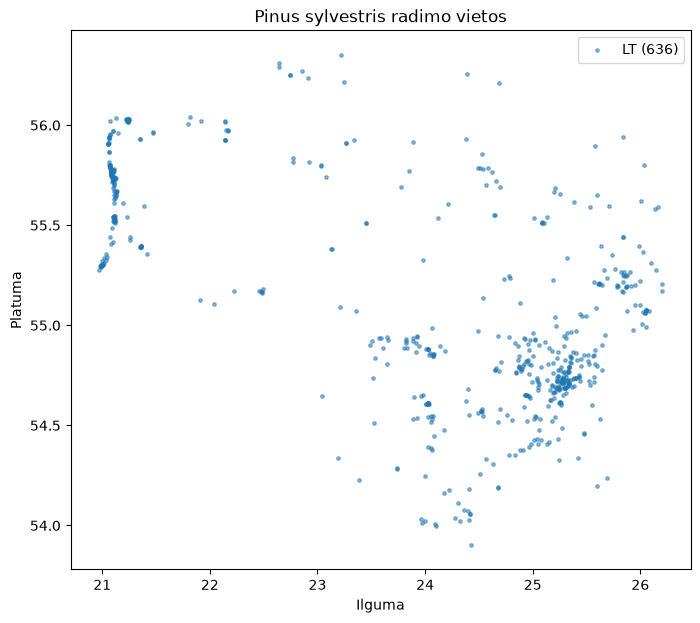

In [17]:
plt.figure(figsize=(8, 7))
for salis, grupe in df.groupby("countryCode"):
    plt.scatter(grupe["decimalLongitude"], grupe["decimalLatitude"],
                s=6, alpha=0.5, label=f"{salis} ({len(grupe)})")
plt.xlabel("Ilguma")
plt.ylabel("Platuma")
plt.title("Pinus sylvestris radimo vietos")
plt.legend()
plt.show()

### 7. Įrašai pagal metus

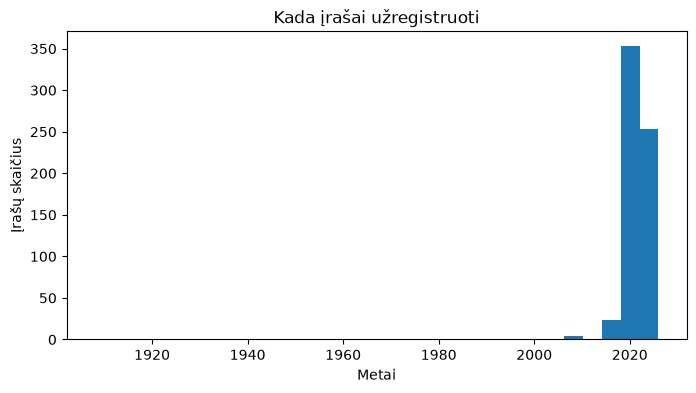

In [18]:
df["year"].dropna().astype(int).plot(kind="hist", bins=30, figsize=(8, 4))
plt.xlabel("Metai")
plt.ylabel("Įrašų skaičius")
plt.title("Kada įrašai užregistruoti")
plt.show()

### 8. Išsaugome išvalytus duomenis kitam žingsniui

In [19]:
df[["gbifID", "countryCode", "decimalLatitude", "decimalLongitude", "year"]].to_csv(
    "pusis_isvalyta.csv", index=False
)
print("Išsaugota: pusis_isvalyta.csv, eilučių:", len(df))

Išsaugota: pusis_isvalyta.csv, eilučių: 636


## Ką užrašyti ataskaitai (skyrius „Duomenų rinkimas“ ir „Ribotumai“)
- Šaltinis: GBIF (nurodykite parsisiuntimo DOI iš GBIF el. laiško ir atsisiuntimo datą).
- Kiek įrašų buvo pradžioje ir kiek liko po kiekvieno valymo žingsnio (rodoma 5 langelyje).
- Dauguma įrašų yra žmonių stebėjimai, todėl jie telkiasi prie kelių ir gyvenviečių.
- Koordinačių tikslumas skiriasi: po valymo 83 % taškų turi nurodytą netikslumą (mediana apie 10 m, didžiausia reikšmė apie 26 km), likusiems 17 % jis nenurodytas.

**Kitas žingsnis (2 dalis):** sugeneruoti neigiamus pavyzdžius („pušies nėra“) ir prijungti dirvožemio savybes iš SoilGrids.